In [1]:
import pandas as pd
import seaborn as sns

In [20]:
tmp = (
    pd.concat([
        pd.concat([
            pd.read_parquet(f"../data/processed/dl19-eval-subsampled-default_fillna_{i}.parquet")
            for i in range(4)
        ]).assign(corpus="dl19"),
        pd.concat([
            pd.read_parquet(f"../data/processed/dl19-eval-subsampled-predicted_fillna_{i}.parquet")
            for i in range(4)
        ]).assign(corpus="dl19"),
         pd.concat([
            pd.read_parquet(f"../data/processed/dl20-eval-subsampled-default_fillna_{i}.parquet")
            for i in range(4)
        ]).assign(corpus="dl20"),
        pd.concat([
            pd.read_parquet(f"../data/processed/dl20-eval-subsampled-predicted_fillna_{i}.parquet")
            for i in range(4)
        ]).assign(corpus="dl20"),
    ])
    .drop(columns=["in_pool", "index", "unjudged_ratio"])
    .assign(
        depth=lambda df: df["metric"].apply(lambda row: int(row.split("@")[-1])),
        metric=lambda df: df["metric"].apply(lambda row: row.split("@")[0])
    )
    .merge(
        (
            pd.concat([
                pd.read_parquet("../data/processed/dl19-eval-original.parquet").assign(corpus="dl19"),
                pd.read_parquet("../data/processed/dl20-eval-original.parquet").assign(corpus="dl20")
            ])
            .drop(columns=["index", "iteration", "unjudged_ratio", "run_sample_rate", "source", "in_pool"])
            .assign(
                depth=lambda df: df["metric"].apply(lambda row: int(row.split("@")[-1])),
                metric=lambda df: df["metric"].apply(lambda row: row.split("@")[0])
            )
        ),
        on=["query", "system", "metric", "depth", "corpus"],
        how="left",
        suffixes=("_predicted", "_oracle")
    )
    .reset_index()
    .drop(columns=["query", "index"])
    .groupby(["system", "depth", "run_sample_rate", "iteration", "source", "metric", "corpus"])
    .mean()
    .reset_index()
)
tmp

,system,depth,run_sample_rate,iteration,source,metric,corpus,value_predicted,value_oracle
0,1,5,0.03,4,filled_0,NDCG,dl20,0.829855,0.932854
1,1,5,0.03,4,filled_0,UNJ,dl20,0.000000,0.007143
2,1,5,0.03,4,filled_1,NDCG,dl20,0.930085,0.932854
3,1,5,0.03,4,filled_1,UNJ,dl20,0.000000,0.007143
4,1,5,0.03,4,predicted_128,NDCG,dl20,0.968098,0.932854
...,...,...,...,...,...,...,...,...,...
207643,test1,1000,0.90,1,predicted_192,UNJ,dl19,0.901586,0.875276
207644,test1,1000,0.90,1,predicted_256,NDCG,dl19,0.773248,0.643376
207645,test1,1000,0.90,1,predicted_256,UNJ,dl19,0.901586,0.875276
207646,test1,1000,0.90,1,predicted_64,NDCG,dl19,0.773662,0.643376


In [21]:
corr = (
    tmp
    .query("metric != 'UNJ'")
    .drop(columns=["metric"])
    .set_index("system")
    .groupby(["run_sample_rate", "iteration", "depth", "source", "corpus"])
    .corr(method="spearman")
    .reset_index()
    .query("level_5 == 'value_oracle'")
    .drop(columns=["level_5", "value_oracle"])
)
corr

,run_sample_rate,iteration,depth,source,corpus,value_predicted
1,0.03,0,5,filled_0,dl19,0.238460
3,0.03,0,5,filled_1,dl19,0.866791
5,0.03,0,5,predicted_128,dl19,0.955514
7,0.03,0,5,predicted_192,dl19,0.944956
9,0.03,0,5,predicted_256,dl19,0.932981
...,...,...,...,...,...,...
6903,0.90,7,1000,filled_1,dl20,1.000000
6905,0.90,7,1000,predicted_128,dl20,1.000000
6907,0.90,7,1000,predicted_192,dl20,1.000000
6909,0.90,7,1000,predicted_256,dl20,1.000000


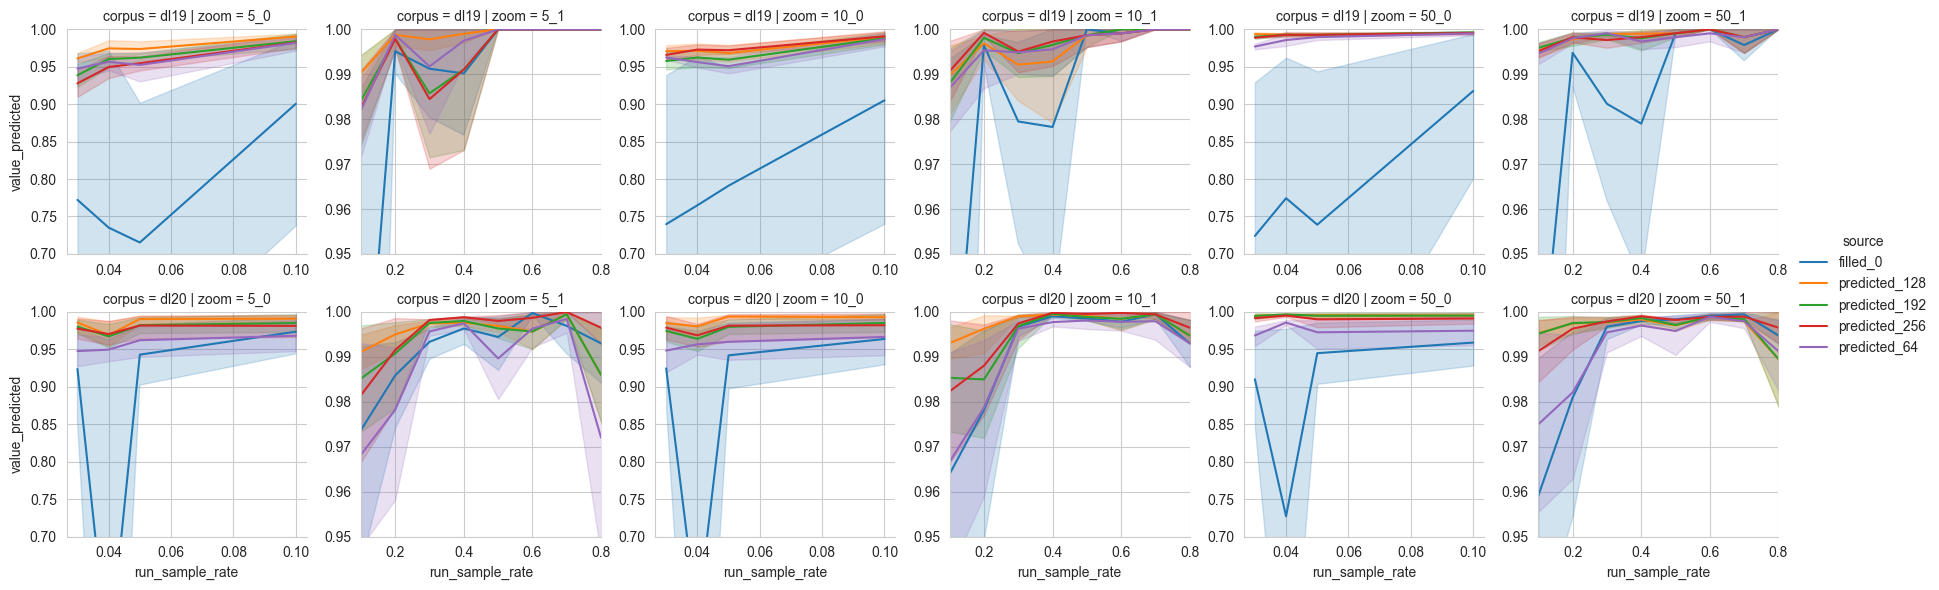

In [41]:
g = sns.FacetGrid(
    data=pd.concat([
        (
            corr
            .query("depth in [5,10,50]")
            .query("source != 'filled_1'")
            .query("run_sample_rate >= 0.1")
            .rename(columns={"depth": "k"})
            .assign(zoom=lambda df: df["k"].astype(str) + "_1")
        ),
        (
            corr
            .query("depth in [5,10,50]")
            .query("source != 'filled_1'")
            .query("run_sample_rate <= 0.1")
            .rename(columns={"depth": "k"})
            .assign(zoom=lambda df: df["k"].astype(str) + "_0")
        )
    ]),
    row="corpus",
    col="zoom",
    hue="source",
    sharey=False,
    sharex=False,
    legend_out=True,
    col_order=["5_0", "5_1", "10_0", "10_1", "50_0", "50_1"],
)
g.map(
    sns.lineplot,
    "run_sample_rate",
    "value_predicted",
)

for ax in g.axes[:, 0]:
    ax.set_ylim(0.7, 1)
for ax in g.axes[:, 2]:
    ax.set_ylim(0.7, 1)
for ax in g.axes[:, 4]:
    ax.set_ylim(0.7, 1)
for ax in g.axes[:, 1]:
    ax.set_ylim(0.95, 1)
    ax.set_xlim(0.1, .8)
for ax in g.axes[:, 3]:
    ax.set_ylim(0.95, 1)
    ax.set_xlim(0.1, .8)
for ax in g.axes[:, 5]:
    ax.set_ylim(0.95, 1)
    ax.set_xlim(0.1, .8)

g.add_legend()
g.savefig("figure-correlation-subsampling.pdf")